# Thí nghiệm E2: Phép nhân × SmolLM2-360M-Instruct (họ Llama)

Cùng bài phép nhân của notebook demo nhưng với một **họ mô hình khác**: SmolLM2 dùng kiến trúc Llama, không phải Qwen. Bộ suy luận nghiêm ngặt của HeteroES hỗ trợ Qwen2, Llama và Mistral. Mô hình gốc hay ghi cả phép tính vào `\boxed{}` (ví dụ `\boxed{879 * 2} = 1758`), nên bộ chấm có sẵn cho 0 điểm gần như mọi câu và ES không có tín hiệu để học. Notebook này dùng một **hàm reward Python tự viết** có điểm từng phần.

Notebook chạy theo đúng luồng của người nghiên cứu trên lab HeteroES:

| Bước | Ở đây |
|---|---|
| Mô hình | `Model.from_hf` ghim một commit Hugging Face; **mỗi máy tự tải từ Hugging Face** và kiểm SHA-256 từng tệp |
| Dữ liệu | `Dataset.from_rows` (train / validation / test cố định, ghim mã băm) |
| Chạy | `ESTrainer.submit(lab, coordinator, workers)`: lab xếp hàng, chia candidate cho các GPU, chấm chéo (audit) |
| Nối tiếp | mỗi đoạn sau bắt đầu từ trọng số cuối đã kiểm chứng của đoạn trước (`derive_model`) |
| Đánh giá | chọn checkpoint bằng validation; tập test chỉ chấm **một lần** ở cuối, kiểm định McNemar |

Các đoạn và lý do chọn tham số nằm ở `decisions/e2-arith-smollm2.json`; mã thí nghiệm trên lab ở `state/e2-arith-smollm2.json`. Chạy lại
notebook sẽ gắn vào các run đã có (không chạy lại). Đặt `CHAY_MOI = True` để chạy một run ngắn mới khi demo.

## 1. Chuẩn bị: kết nối lab và xem các GPU

In [1]:
import json
import sys
import time
from pathlib import Path

HERE = Path.cwd()
SRC = (HERE / ".." / ".." / "src").resolve()  # runtime/notebooks/experiments -> runtime/src
for path in (str(SRC), str(HERE)):
    if path not in sys.path:
        sys.path.insert(0, path)

import runner  # noqa: E402  (sets a clean Hugging Face cache first)
import tasks  # noqa: E402
from heteroes.sdk import ESConfig, ESTrainer, reward  # noqa: E402
from heteroes.sdk_lab import Dataset, Lab, Model  # noqa: E402

NAME = 'e2-arith-smollm2'
CHAY_MOI = False  # True: a short new run for a live demo (a few generations) instead of re-attaching to the recorded one
COORDINATOR = "5070ti-nhan"  # the coordinator goes to a GPU (owner rule)
EXCLUDE = set()  # names of devices to leave out of a new segment

experiment = runner.Experiment(NAME + (time.strftime("-demo-%Y%m%d-%H%M") if CHAY_MOI else ""))
lab = Lab.from_session()  # python3 scripts/lab-login.py signs in once (12 hours)


def online_workers():
    return [d.name for d in lab.devices() if d.online and d.on and not d.cpu_only and d.name not in EXCLUDE]


for d in lab.devices():
    print(f"{d.name:16} {d.gpu:28} {d.vram_gb:5.1f} GB  online={d.online} ON={d.on} bận={d.busy}")

5070ti-nhan      NVIDIA GeForce RTX 5070 Ti    15.9 GB  online=True ON=True bận=True


## 2. Dữ liệu

In [2]:
from heteroes.v3 import data as v3data

splits = v3data.build(tasks.arithmetic(), split_seed=42)["splits"]  # the same seeded 80/10/10 split as the demo
splits = {k: [dict(r) for r in v] for k, v in splits.items()}
data = Dataset.from_rows(**splits, directory=experiment.dir / "data")
print({k: len(v) for k, v in splits.items()}, "| mã băm dữ liệu", data.sha256[:16], "…")
print(splits["test"][0]["prompt"], "→ đáp án", splits["test"][0]["answer"])

{'train': 2400, 'validation': 300, 'test': 300} | mã băm dữ liệu 00c9483955315fdd …
What is 80 * 37? Reply with only the final number inside \boxed{}, no explanation. → đáp án 2960


## 3. Mô hình

`HuggingFaceTB/SmolLM2-360M-Instruct` được ghim theo commit `a10cc1512eab…`. Trên lab đây là mô hình **tham chiếu**: lab không giữ bản
sao, mỗi worker tự tải từ Hugging Face rồi kiểm tra mã băm từng tệp trước khi làm việc.

In [3]:
model = Model.from_hf('HuggingFaceTB/SmolLM2-360M-Instruct', revision='a10cc1512eabd3dde888204e902eca88bddb4951')
print(model.id, model.revision[:12], model.source)
for file, sha in model.manifest["files"].items():
    print(f"  {file:28} {sha[:16]}…")

/home/pc5070ti/miniforge3/envs/heteroes-match/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Fetching 12 files: 100%|██████████| 12/12 [00:00<00:00, 3263.20it/s]

HuggingFaceTB/SmolLM2-360M-Instruct a10cc1512eab REFERENCE
  all_results.json             71face5e244d7848…
  config.json                  224f72354f10d617…
  eval_results.json            db9bcb5c4f2a3be0…
  generation_config.json       87b916edaaab66b3…
  merges.txt                   0b54e8aa4e53d538…
  model.safetensors            e6bffe7435d7ddc1…
  special_tokens_map.json      2b7379f3ae813529…
  tokenizer.json               9ca9acddb6525a19…
  tokenizer_config.json        4ec77d44f62efeb3…
  train_results.json           fceae2634b0a268a…
  trainer_state.json           2263f580ae0d7890…
  vocab.json                   82b84012e3add4d0…


## 4. Reward

Reward của một candidate là trung bình điểm trên lô 32 câu train. Trên tập test, **"đúng" nghĩa là điểm 1** (đáp án
chính xác).

In [4]:
@reward("arith-shaped@1")
def arith_shaped(completions, rows):
    """1 when the boxed number is the answer, 0.5 when the answer appears elsewhere, 0.1 for a box, else 0."""
    import re

    out = []
    for text, row in zip(completions, rows):
        boxed = re.findall(r"\\boxed\{([^{}]*)\}", text)
        if boxed and boxed[-1].strip().replace(",", "") == row["answer"]:
            out.append(1.0)
        elif re.search(r"(?<![\d.])" + re.escape(row["answer"]) + r"(?![\d.])", text):
            out.append(0.5)
        elif boxed:
            out.append(0.1)
        else:
            out.append(0.0)
    return out


TEST_SCORER = {"name": "boxed-number", "config": {"answerField": "answer", "formatReward": 0.1}}  # strict on test
make_reward = dict(reward_func=arith_shaped)
demo = splits["test"][0]
texts = [f"\\boxed{{{demo['answer']}}}", f"\\boxed{{1 * 2}} = {demo['answer']}", "\\boxed{7}", "không biết"]
print(list(zip(texts, arith_shaped(texts, [demo] * len(texts)))))

[('\\boxed{2960}', 1.0), ('\\boxed{1 * 2} = 2960', 0.5), ('\\boxed{7}', 0.1), ('không biết', 0.0)]


### Mô hình gốc trả lời thế nào?

Ba câu test đầu, giải mã tham lam bằng bộ suy luận nghiêm ngặt `strict_b22_v1` như trong thí nghiệm (tối đa 24
token).

In [5]:
sample = splits["test"][:3]
before = runner.score_model(model.path, sample, TEST_SCORER, 24)
for row, text, s in zip(sample, before["outputs"], before["scores"]):
    print(f"[điểm {s}]", repr(text[-300:]))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 6415.27it/s]

[điểm 0.0] '\\boxed{80 * 37} = 2840'
[điểm 0.0] '\\boxed{54 * 45} = 2300'
[điểm 0.0] '\\boxed{717 * 4 = 2868}'


## 5. Cấu hình

32 candidate mỗi thế hệ, mỗi candidate chấm trên 32 câu train; σ và α theo từng đoạn. Validation
(tập validation) được chấm mỗi 10 thế hệ trên coordinator.

In [6]:
def make_trainer(model, segment):
    args = ESConfig(
        model=model,
        dataset=data,
        population=32,
        batch_size=32,
        generations=3 if CHAY_MOI else segment["generations"],
        alpha=segment["alpha"],
        sigma=segment["sigma"],
        max_new_tokens=24,
        eval_dtype="float16",
        decoder="strict_b22_v1",  # same tokens on every supported NVIDIA GPU
        eval_chunk=32,
        validation_interval=10,
        audit_rate=0.05,
    )
    return ESTrainer(args, code_dir=experiment.dir / "code", **make_reward)


segments = experiment.segments({'alpha': 0.0005, 'sigma': 0.001, 'generations': 60, 'reason': 'tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate'})
for i, s in enumerate(segments, 1):
    print(f"đoạn {i}: α={s['alpha']} σ={s['sigma']} {s['generations']} thế hệ — {s['reason']}")

đoạn 1: α=0.0005 σ=0.001 60 thế hệ — tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate
đoạn 2: α=0.002 σ=0.001 60 thế hệ — đoạn 1 (α 5·10⁻⁴): reward train chỉ 0,21→0,25, validation đứng yên 0,243→0,240 và test không đổi một câu nào; bước cập nhật quá nhỏ để đổi câu trả lời tham lam của SmolLM2, nên tăng α gấp 4


## 6. Chạy trên lab

Mỗi đoạn là một experiment trên lab. Ô này chờ đến khi các đoạn xong (xem trực tiếp trên trang Experiments của lab);
khi chạy lại notebook, các đoạn đã có chỉ được gắn lại.

In [7]:
runs = runner.run_segments(lab, experiment, model, make_trainer, segments, COORDINATOR, online_workers)
for (segment, run, _), i in zip(runs, range(1, len(runs) + 1)):
    print(f"đoạn {i}: {run.id} {run.status()} {run.url}")

segment-01: đã có run 3fde8df70e134d30860ed60c0abd1cb4


segment-02: α=0.002 σ=0.001 60 thế hệ trên ['5070ti-nhan'] — lý do: đoạn 1 (α 5·10⁻⁴): reward train chỉ 0,21→0,25, validation đứng yên 0,243→0,240 và test không đổi một câu nào; bước cập nhật quá nhỏ để đổi câu trả lời tham lam của SmolLM2, nên tăng α gấp 4


  chờ ['5070ti-nhan'] rảnh…


Qualifying 5070ti-nhan for HuggingFaceTB/SmolLM2-360M-Instruct+e2-arith-smollm2-s01 (a few minutes)…


  5070ti-nhan: qualified


Queued 5afd1b89ae9b4590bc8b7aff77068400: https://lab.heteroes.site/experiments/5afd1b89ae9b4590bc8b7aff77068400


đoạn 1: 3fde8df70e134d30860ed60c0abd1cb4 COMPLETED https://lab.heteroes.site/experiments/3fde8df70e134d30860ed60c0abd1cb4


đoạn 2: 5afd1b89ae9b4590bc8b7aff77068400 COMPLETED https://lab.heteroes.site/experiments/5afd1b89ae9b4590bc8b7aff77068400


## 7. Quá trình học

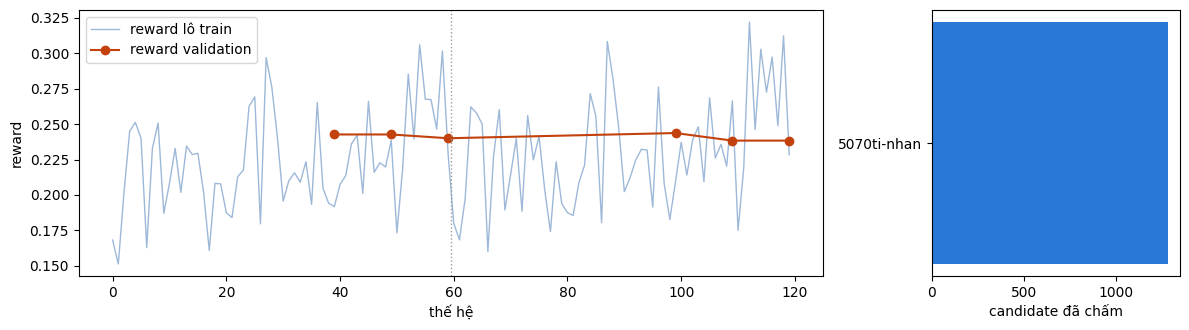

validation: [(39, 0.2427), (49, 0.2427), (59, 0.24), (99, 0.2437), (109, 0.2383), (119, 0.2383)]


In [8]:
import matplotlib.pyplot as plt

rewards, validation, work = runner.history(runs)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [3, 1]})
a.plot([g for g, _ in rewards], [r for _, r in rewards], color="#9db8d8", lw=1, label="reward lô train")
a.plot([g for g, _ in validation], [r for _, r in validation], "o-", color="#c2410c", label="reward validation")
for end in [sum(s["generations"] for s, _, _ in runs[:k]) for k in range(1, len(runs))]:
    a.axvline(end - 0.5, color="#999", ls=":", lw=1)
a.set_xlabel("thế hệ")
a.set_ylabel("reward")
a.legend()
names = {d.worker_id: d.name for d in lab.devices()}
b.barh([names.get(w, w) for w in work], list(work.values()), color="#2a78d6")
b.set_xlabel("candidate đã chấm")
plt.tight_layout()
plt.show()
print("validation:", [(g, round(r, 4)) for g, r in validation])

## 8. Chọn checkpoint và chấm test (một lần)

Checkpoint được chọn là cuối đoạn có reward validation cao nhất. Tập test được chấm cho mô hình gốc, cuối đoạn đầu và
checkpoint được chọn; kết quả lưu lại nên chạy lại notebook không chấm lại.

In [9]:
ends = []
for k, (segment, run, _) in enumerate(runs, 1):
    marks = [v for v in run.results()["validation"] if v["generation"] is not None]
    ends.append((marks[-1]["reward"], k))
best = max(ends)[1]
print("validation cuối mỗi đoạn:", ends, "→ chọn đoạn", best)

done = [(s, r, m) for s, r, m in runs]
first_dir = runner.after_segment(lab, experiment, done, 1).path
best_dir = runner.after_segment(lab, experiment, done, best).path
rows = splits["test"]
base = runner.test_report(experiment, "base", -1, model.path, rows, TEST_SCORER, 24)
first = runner.test_report(experiment, "first", 1, first_dir, rows, TEST_SCORER, 24)
chosen = runner.test_report(experiment, f"segment-{best:02d}", best, best_dir, rows, TEST_SCORER, 24)
for label, report in (("mô hình gốc", base), ("cuối đoạn 1", first), (f"chọn (đoạn {best})", chosen)):
    ok, n = runner.correct(report)
    print(f"{label:16} đúng {ok}/{n} = {ok / n:6.1%}   reward {report['checkpoints'][0]['meanReward']:.4f}")

validation cuối mỗi đoạn: [(0.24, 1), (0.23833333333333334, 2)] → chọn đoạn 1


mô hình gốc      đúng 0/300 =   0.0%   reward 0.0003
cuối đoạn 1      đúng 0/300 =   0.0%   reward 0.0003
chọn (đoạn 1)    đúng 0/300 =   0.0%   reward 0.0003


In [10]:
from heteroes.v3.comparison import compare

result = compare(base, chosen)
print(f"gốc → chọn: sửa đúng {result['fixed']}, làm sai {result['broke']}, McNemar p = {result['mcnemarExactP']:.2g}, "
      f"khoảng tin cậy 95% của mức tăng reward [{result['bootstrapCI'][0]:.3f}; {result['bootstrapCI'][1]:.3f}]")
if best != 1:
    later = compare(first, chosen)
    print(f"đoạn 1 → chọn: sửa {later['fixed']}, làm sai {later['broke']}, p = {later['mcnemarExactP']:.2g}")

gốc → chọn: sửa đúng 0, làm sai 0, McNemar p = 1, khoảng tin cậy 95% của mức tăng reward [0.000; 0.000]


## 9. Ví dụ trước / sau

In [11]:
shown = 0
for i, row in enumerate(rows):
    a, b = base["checkpoints"][0], chosen["checkpoints"][0]
    if a["scores"][i] != 1 and b["scores"][i] == 1:
        print("—", row["prompt"][:200].replace("\n", " "))
        print("  gốc :", repr(a["outputs"][i][-200:]))
        print("  sau :", repr(b["outputs"][i][-200:]))
        shown += 1
    if shown == 3:
        break

## 10. Lưu tóm tắt (cho notebook tổng hợp)

In [12]:
summary = {
    "name": NAME, "model": model.id, "revision": model.revision, "segments": [{**s, "experimentId": r.id} for s, r, _ in runs],
    "validation": validation, "workPerDevice": {names.get(w, w): c for w, c in work.items()},
    "test": {label: dict(zip(("correct", "count"), runner.correct(rep))) | {"meanReward": rep["checkpoints"][0]["meanReward"]}
             for label, rep in (("base", base), ("first", first), ("selected", chosen))},
    "selectedSegment": best, "comparison": result,
}
out = runner.HERE / "results" / f"{experiment.name}.json"
out.parent.mkdir(exist_ok=True)
out.write_text(json.dumps(summary, indent=1, ensure_ascii=False) + "\n")
print("đã lưu", out)

đã lưu /home/pc5070ti/projects/heteroes/runtime/notebooks/experiments/results/e2-arith-smollm2.json
